# BANKING77 — EDA and light cleaning

Explore training requests with pandas; use Hugging Face datasets directly for training. Nothing needs to be exported or reloaded as CSV. The official test split stays untouched for final evaluation.

Select the project `.venv` kernel. Run the installation cell only when setting up an environment.


In [ ]:
import sys
!{sys.executable} -m pip install datasets pandas matplotlib scikit-learn

In [1]:
from datasets import load_dataset

ds = load_dataset("PolyAI/banking77")

/Users/quocjacob/.pyenv/versions/3.13.15/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Using the latest cached version of the dataset since PolyAI/banking77 couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/quocjacob/Desktop/hub-banking-support-ticket-routing/.cache/huggingface/datasets/PolyAI___banking77/default/0.0.0/1846984189f2bc0ac51c6fc3a600fa9e1714e0c6 (last modified on Fri Nov  6 23:10:25 2026).


In [2]:
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd


## 1. Look at the training data

Read intent names from the dataset metadata so their IDs stay correct.

In [3]:
labels = ds["train"].features["label"].names
train = ds["train"].to_pandas().rename(columns={"text": "raw_text"})
train["row_id"] = [f"train_{i:05d}" for i in train.index]
train["intent"] = train["label"].map(dict(enumerate(labels)))

print(f"Training requests: {len(train):,} | Intents: {len(labels)}")
display(train.sample(5, random_state=42))
display(train.isna().sum().rename("missing values").to_frame())
print("Blank requests:", train["raw_text"].str.strip().eq("").sum())
print("Exact duplicate requests:", train["raw_text"].duplicated().sum())

Training requests: 10,003 | Intents: 77


,raw_text,label,row_id,intent
6883,Is it possible for me to change my PIN number?,21,train_06883,change_pin
5836,I'm not sure why my card didn't work,25,train_05836,declined_card_payment
8601,I don't think my top up worked,59,train_08601,top_up_failed
2545,Can you explain why my payment was charged a fee?,15,train_02545,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,5,train_08697,balance_not_updated_after_bank_transfer


,missing values
raw_text,0
label,0
row_id,0
intent,0


Blank requests: 0
Exact duplicate requests: 0


## 2. Intent balance and request lengths

Use whitespace word counts for a quick length overview. These are not transformer token lengths.

,requests per intent
count,77.000000
mean,129.909091
std,32.942207
min,35.000000
25%,112.000000
50%,127.000000
75%,159.000000
max,187.000000


,word_count,character_count
count,10003.000000,10003.000000
mean,11.949415,59.473758
std,7.891577,40.867901
min,2.000000,13.000000
50%,10.000000,47.000000
90%,22.000000,109.800000
95%,29.000000,151.900000
99%,43.000000,220.980000
max,79.000000,433.000000


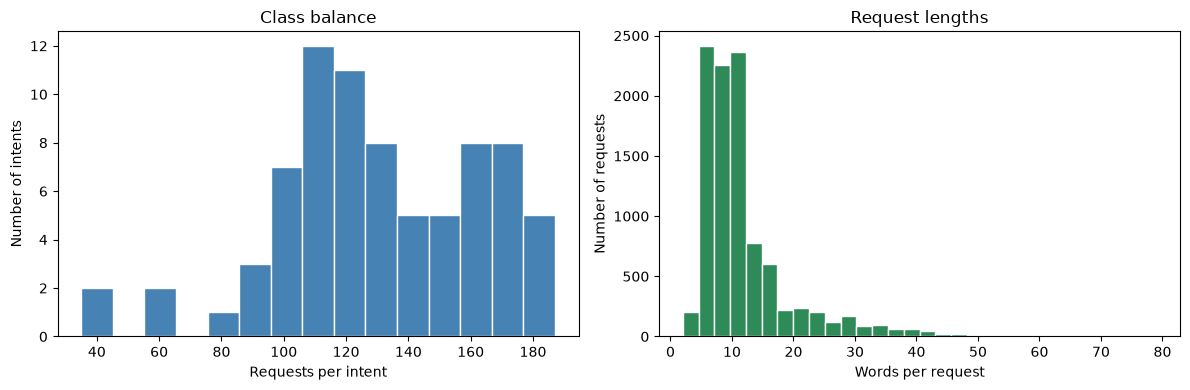

,requests
intent,
contactless_not_working,35
virtual_card_not_working,41
card_acceptance,59
card_swallowed,61
lost_or_stolen_card,82
cash_withdrawal_charge,177
wrong_amount_of_cash_received,180
balance_not_updated_after_cheque_or_cash_deposit,181
direct_debit_payment_not_recognised,182


In [4]:
intent_counts = train["intent"].value_counts().sort_values()
train["word_count"] = train["raw_text"].str.split().str.len()
train["character_count"] = train["raw_text"].str.len()

display(intent_counts.describe().to_frame("requests per intent"))
display(train[["word_count", "character_count"]].describe(percentiles=[.5, .9, .95, .99]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(intent_counts, bins=15, color="steelblue", edgecolor="white")
axes[0].set(xlabel="Requests per intent", ylabel="Number of intents", title="Class balance")
axes[1].hist(train["word_count"], bins=30, color="seagreen", edgecolor="white")
axes[1].set(xlabel="Words per request", ylabel="Number of requests", title="Request lengths")
plt.tight_layout()
plt.show()

display(pd.concat([intent_counts.head(5), intent_counts.tail(5)]).to_frame("requests"))

## 3. Light cleaning and duplicate check

`clean_text()` normalizes Unicode and collapses whitespace, preserving case, punctuation, numbers, and negation. Keep `raw_text` alongside `text_clean` for inspection. The separate case-insensitive key is only for auditing duplicates.


In [5]:
def clean_text(text):
    return " ".join(unicodedata.normalize("NFC", text).split())


def duplicate_key(text):
    return " ".join(unicodedata.normalize("NFKC", text).casefold().split())


train["text_clean"] = train["raw_text"].map(clean_text)
train["duplicate_key"] = train["raw_text"].map(duplicate_key)

display(train[["raw_text", "text_clean", "intent"]].sample(5, random_state=42))

duplicates = train[train["duplicate_key"].duplicated(keep=False)]
print("Duplicate groups after normalization:", duplicates["duplicate_key"].nunique())
print("Groups with conflicting labels:", train.groupby("duplicate_key")["label"].nunique().gt(1).sum())
display(duplicates.sort_values("duplicate_key")[["row_id", "raw_text", "intent"]])

,raw_text,text_clean,intent
6883,Is it possible for me to change my PIN number?,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer


Duplicate groups after normalization: 4
Groups with conflicting labels: 0


,row_id,raw_text,intent
6910,train_06910,Do I need to go to a physical bank to change m...,change_pin
6965,train_06965,\nDo I need to go to a physical bank to change...,change_pin
1246,train_01246,I can't seem to be able to use my card,card_not_working
1290,train_01290,\nI can't seem to be able to use my card\n\n\n,card_not_working
1710,train_01710,\nI put the wrong pin too many times and now i...,pin_blocked
1724,train_01724,I put the wrong pin too many times and now it ...,pin_blocked
4594,train_04594,Where can I withdraw money from?,atm_support
4595,train_04595,\nWhere can I withdraw money from?,atm_support


## 4. Split with Hugging Face

Use one native stratified split: 90% for training and 10% for validation. This leaves at least 30 training requests in every intent for the few-shot comparison. All training notebooks use this call with seed 42. Labels already come from dataset metadata.

These are row-based splits, so normalized duplicates can cross partitions; the check below reports that limitation. The previous group-based CSV split is a different experiment.


In [6]:
split = ds["train"].train_test_split(test_size=0.1, stratify_by_column="label", seed=42)
train_ds = split["train"]
valid_ds = split["test"]

print(f"Train: {len(train_ds):,} | Validation: {len(valid_ds):,}")
train_keys = set(map(duplicate_key, train_ds["text"]))
print("Normalized train/validation overlap:", len(train_keys & set(map(duplicate_key, valid_ds["text"]))))


Train: 9,002 | Validation: 1,001


Normalized train/validation overlap: 1


## 5. Continue to training

Open `training.ipynb` for TF-IDF/MiniLM or `training_transformer.ipynb` for DistilBERT/RoBERTa. Each loads BANKING77 directly and recreates the same native splits; preprocessing is an EDA notebook, not a required data-export step.

Training uses the same Unicode/whitespace cleaning followed by each model's own tokenizer. No lemmatization or punctuation removal is applied.


## References

- [Casanueva et al. (2020), BANKING77 and dual sentence encoders](https://aclanthology.org/2020.nlp4convai-1.5/): dataset and frozen-encoder motivation.
- [Reimers & Gurevych (2019), Sentence-BERT](https://aclanthology.org/D19-1410/): sentence embeddings for cosine similarity.
- [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2): use the encoder's own tokenizer and pooling.
- [BANKING77 dataset card](https://huggingface.co/datasets/PolyAI/banking77): source and CC-BY-4.0 attribution.

These sources inform the pipeline; this notebook does not claim state-of-the-art results or reproduce a paper's evaluation.